In [1]:
import pandas as pd
import numpy as np

### 1. Load Data

In [2]:
df=pd.read_csv("powerplant_data.csv")

In [3]:
df.head()

,AT,V,AP,RH,PE
0,8.34,40.77,1010.84,90.01,480.48
1,23.64,58.49,1011.40,74.20,445.75
2,29.74,56.90,1007.15,41.91,438.76
3,19.07,49.69,1007.22,76.79,453.09
4,11.80,40.66,1017.13,97.20,464.43


In [4]:
# AT= temperature
# V= Vacuume
# AP = Atmospeheric pressure
# RH = Humidity

##### Preprocessing (TrainTestSplit + Scaling)

In [5]:
from sklearn.model_selection import train_test_split
X=df.drop("PE",axis=1)
y=df["PE"]

X_train,X_test,y_train,y_test=train_test_split(
    X,y,test_size=0.2,random_state=42
)

In [6]:
from sklearn.preprocessing import StandardScaler

Scaler=StandardScaler()

X_train_Scaled=Scaler.fit_transform(X_train)
X_test_Scaled=Scaler.transform(X_test)

### 2. Data to Tensor

In [7]:
import torch 
import torch.nn as nn

X_train_tensor=torch.tensor(X_train_Scaled,dtype=torch.float32)
X_test_tensor=torch.tensor(X_test_Scaled,dtype=torch.float32)

print(type(X_train_Scaled))
print(type(y_train))
print(y.shape)

<class 'numpy.ndarray'>
<class 'pandas.core.series.Series'>
(9568,)


In [8]:
# we are passing X_train_Scaled aned X_test_Scaled directly 
# as they are numpy arrays

#But we have to pass Values of y_train and y_test as they are pandas's core series

#What is view(-1,1) --> Right now our data is in 1D [1,2,3,4,5]
# we want them in 2d 
# [[1],
#  [2],
#  [3],
#  [4],
#  [5]
# ]

# View(-1,1) will do that (-1->row and 1->column)

In [9]:
y_train_tensor=torch.tensor(y_train.values,dtype=torch.float32).view(-1,1)
y_test_tensor=torch.tensor(y_test.values,dtype=torch.float32).view(-1,1)

### 3. Tensor Dataset and Tensor Loder

In [10]:
# Dataloader will partition dataset into tensors but cannot directly access data stored in memory
# TensorDataset can access data from memory directly
# So first data->TensorDataset
#    TensorDataSet->DataLoader              

In [11]:
from torch.utils.data import TensorDataset, DataLoader

#here whole train+test data will be given to model to create TensorDataset
#(1) Tensor loaded in Datasets
trainDataset=TensorDataset(X_train_tensor,y_train_tensor)
testDataset=TensorDataset(X_test_tensor,y_test_tensor)

#(2) Datasets to DataLoader
trainLoader=DataLoader(trainDataset,batch_size=32,shuffle=True)
testLoader=DataLoader(testDataset,batch_size=32)

### 4. Define ANN model

In [12]:
class ANN(nn.Module):
    def __init__(self):
        super(ANN,self).__init__()
        
        self.model=nn.Sequential(
            
            #1st hidden Layer
            nn.Linear(X_train.shape[1],6),
            nn.ReLU(),
            
            #2nd hidden Layer
            nn.Linear(6,6),
            nn.ReLU(),
            
            #Answer
            nn.Linear(6,1)
        )
    def forward(self,x):
        return self.model(x)

In [13]:
# in definition we have to provide LossFunction and Optimizers as well
# In torch, Loss function is inBuilt but we have to define Optimizers externally
import torch.optim as optim

model=ANN()

lossFunction=nn.MSELoss()
optimizer=optim.Adam(model.parameters())

### 5. Train Model && 6. Eveluate mode

In [14]:
# We will use 100 EPOCHES
# 1 Epoch means Whole dataset is transffered once
epochs=100;
train_losses=[]
validation_losses=[]

minimumValidationLoss=float("inf")

#training
for epoch in range(epochs):
    
    model.train()
    
    currentLoss=0.0
    
    #xb->1 batch's feature
    #yb->1 batch's answers
    for xb,yb in trainLoader:    
        optimizer.zero_grad()
        
        output=model(xb)
        loss=lossFunction(output,yb)
        loss.backward()
        optimizer.step()
        
        currentLoss+=loss.item()
    
    epoch_train_loss=currentLoss/len(trainLoader)
    train_losses.append(epoch_train_loss)
    
    #validation
    model.eval()
    currentValidationLoss=0.0
    
    with torch.no_grad():        # no gradient compute in testing
        for xb,yb in testLoader:    
            optimizer.zero_grad()

            output=model(xb)
            loss=lossFunction(output,yb)
            # loss.backward()
            optimizer.step()

            currentValidationLoss+=loss.item()
    
    epoch_validation_loss=currentValidationLoss/len(testLoader)
    validation_losses.append(epoch_validation_loss)
    
    if(epoch_validation_loss < minimumValidationLoss):
        minimumValidationLoss=epoch_validation_loss
        torch.save(model.state_dict(),"BestModel.pt") #.pt or .pth
    
    print(f"EPOCH {epoch+1}/{epochs}==> train loss= {epoch_train_loss} & validation loss={epoch_validation_loss}")

EPOCH 1/100==> train loss= 206205.17076822917 & validation loss=205006.87786458334
EPOCH 2/100==> train loss= 200811.324609375 & validation loss=193382.63697916668
EPOCH 3/100==> train loss= 177579.08548177083 & validation loss=156289.09010416668
EPOCH 4/100==> train loss= 128687.03590494792 & validation loss=99351.35221354167
EPOCH 5/100==> train loss= 73284.70872395833 & validation loss=50446.25286458333
EPOCH 6/100==> train loss= 36875.85776367188 & validation loss=27087.547916666666
EPOCH 7/100==> train loss= 22721.735469563802 & validation loss=19359.75359700521
EPOCH 8/100==> train loss= 17528.50360514323 & validation loss=15454.730582682292
EPOCH 9/100==> train loss= 14022.448364257812 & validation loss=12195.483951822916
EPOCH 10/100==> train loss= 10838.440972900391 & validation loss=9296.209285481771
EPOCH 11/100==> train loss= 8145.892433675131 & validation loss=6892.68476969401
EPOCH 12/100==> train loss= 5968.124246215821 & validation loss=4944.711311848959
EPOCH 13/100==>

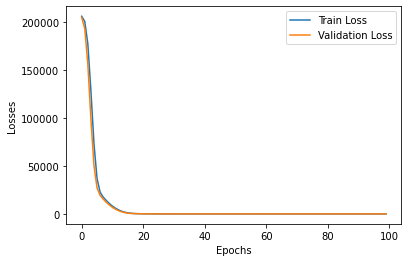

In [15]:
import matplotlib.pyplot as plt

df=pd.DataFrame({
    "Train Loss":train_losses,
    "Validation Loss": validation_losses
})

plt.plot(df["Train Loss"],label="Train Loss")
plt.plot(df["Validation Loss"],label="Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("Losses")

plt.legend()

### Saving and Loading Best Model

In [16]:
# TO save the model, we can do it while performing our training, what we will do is, First we will store minimum loss. But there are 2 losses, first is training loss and another is 
# validation loss, so which loss should we consider minimum to gain best model? Answer is validation loss. As in training, we are doing backward propogation, which itself do learning and 
# try to reduce the trining loss, so our task is to minimize the validation loss

In [20]:
# We have saved our model and now our work is to load that model for future so we dont have to perform this everytime
model.load_state_dict(torch.load("BestModel.pt"))

<All keys matched successfully>

### Eveluate Model

In [21]:
model.eval()
with torch.no_grad():
    trainingPrediction=model(X_train_tensor)
    testingPrediction=model(X_test_tensor)
    
    trainingMseLoss=lossFunction(trainingPrediction,y_train_tensor)
    testingMseLoss=lossFunction(testingPrediction,y_test_tensor)

print("Training MSE =>", trainingMseLoss.item())
print("Testing MSE =>", testingMseLoss.item())

Training MSE => 20.677722930908203
Testing MSE => 19.10649871826172


In [22]:
from sklearn.metrics import r2_score
print("R2 score =>" , r2_score(y_test,testingPrediction))

R2 score => 0.9332277208683888


In [25]:
# Visulize data side by side
predictedDataFrame=pd.DataFrame(testingPrediction.numpy(),columns=["Predict"])
actualDataFrame=pd.DataFrame(y_test.values,columns=["Actual"])

pd.concat([predictedDataFrame,actualDataFrame],axis=1)

,Predict,Actual
0,435.339539,433.27
1,437.249084,438.16
2,461.333984,458.42
3,476.357361,480.82
4,435.385376,441.41
...,...,...
1909,451.543091,456.70
1910,431.858826,438.04
1911,467.552063,467.80
1912,431.325623,437.14
